<a href="https://colab.research.google.com/github/willbrito86/App_IMC/blob/main/AtividadePratica2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dados antes da limpeza: (344, 7)
Dados após limpeza: (333, 7)


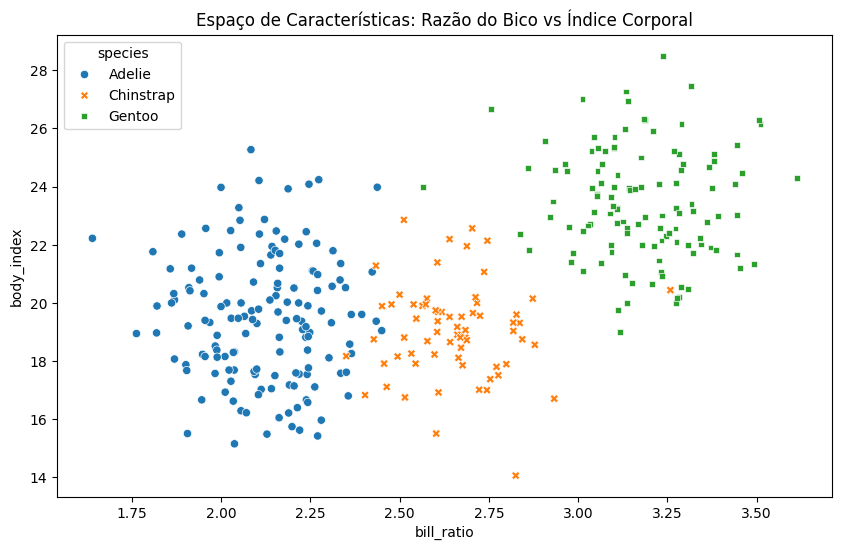

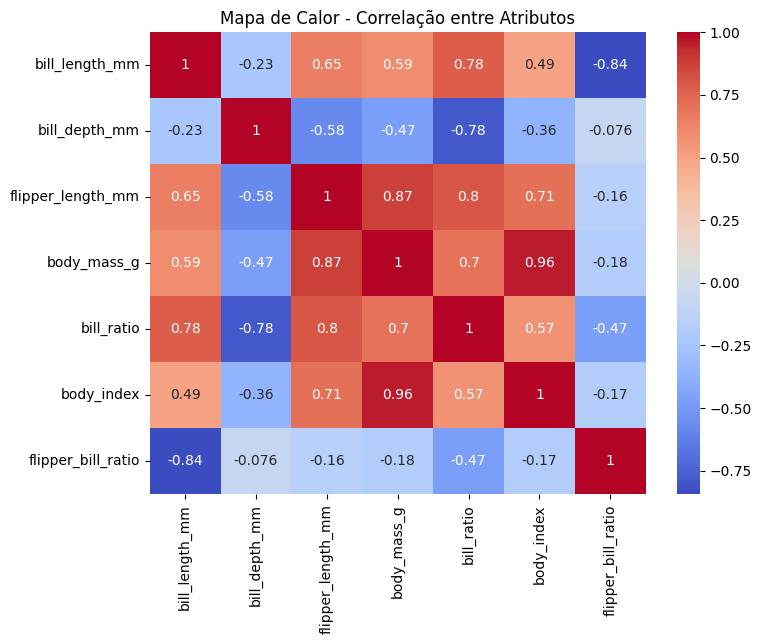

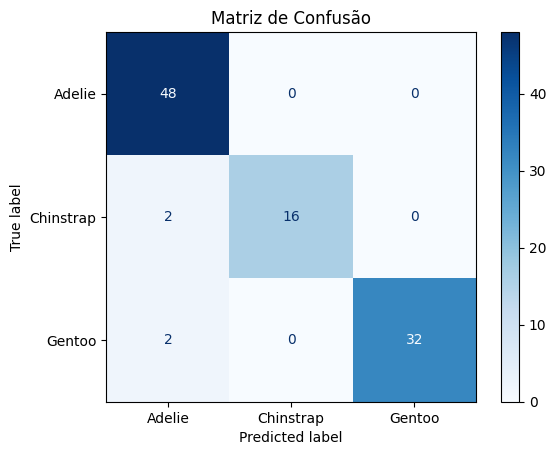


RELATÓRIO DE DESEMPENHO
              precision    recall  f1-score   support

      Adelie       0.92      1.00      0.96        48
   Chinstrap       1.00      0.89      0.94        18
      Gentoo       1.00      0.94      0.97        34

    accuracy                           0.96       100
   macro avg       0.97      0.94      0.96       100
weighted avg       0.96      0.96      0.96       100



In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, ConfusionMatrixDisplay

#CARREGAMENTO E LIMPEZA
df = sns.load_dataset('penguins')

# Identificando e removendo ruídos (nulos)
print(f"Dados antes da limpeza: {df.shape}")
df_clean = df.dropna().copy()
print(f"Dados após limpeza: {df_clean.shape}")

#ENGENHARIA DE ATRIBUTOS (Feature Engineering)
df_clean['bill_ratio'] = df_clean['bill_length_mm'] / df_clean['bill_depth_mm']
df_clean['body_index'] = df_clean['body_mass_g'] / (df_clean['flipper_length_mm'])
df_clean['flipper_bill_ratio'] = df_clean['flipper_length_mm'] / df_clean['bill_length_mm']

#Gerando o gráfico de dispersão para o relatório
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clean, x='bill_ratio', y='body_index', hue='species', style='species')
plt.title('Espaço de Características: Razão do Bico vs Índice Corporal')
plt.show()

#Mapa de Calor
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm')
plt.title('Mapa de Calor - Correlação entre Atributos')
plt.show()

#PREPARAÇÃO DOS DADOS E TREINAMENTO
features = ['bill_ratio', 'body_index', 'flipper_bill_ratio']
X = df_clean[features]
y = df_clean['species']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

#Implementação do KNN
modelo_knn = KNeighborsClassifier(n_neighbors=5)
modelo_knn.fit(X_train, y_train)

#RESULTADOS
y_predito = modelo_knn.predict(X_test)

# Matriz de Confusão
cm = confusion_matrix(y_test, y_predito)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=modelo_knn.classes_)
disp.plot(cmap='Blues')
plt.title('Matriz de Confusão')
plt.show()

print('\n' + '='*40)
print('RELATÓRIO DE DESEMPENHO')
print('='*40)
print(classification_report(y_test, y_predito))